# Red neuronal profunda para estimar la calidad de un jugador de fútbol (SGD + Momentum)

**Asignatura:** Aprendizaje Automático II · Grado en Ciencia de Datos e Inteligencia Artificial (UPM) · curso 2025-26

## El problema

A partir de **22 habilidades** de un jugador de FIFA 19 (regate, pase corto, reacciones, compostura, etc.), se quiere predecir su **calidad global** (*overall score*), discretizada en 4 clases según sus cuartiles:

| Clase | Overall |
|---|---|
| Poor | 46 – 62 |
| Intermediate | 63 – 66 |
| Good | 67 – 71 |
| Excellent | 72 – 94 |

- **Datos:** 16.134 jugadores tras la limpieza (ver `preparacion_datos.ipynb`), divididos en **80 % entrenamiento / 10 % desarrollo (dev) / 10 % test**, de forma estratificada.
- **Referencia:** el enunciado fija un **error bayesiano del 10 %**, el error que cometería un ojeador experto. Es el mínimo alcanzable, así que el objetivo es acercarse a un **90 % de *accuracy***.

## Metodología

Se usa siempre el optimizador **SGD con momentum** y se ajustan los hiperparámetros **de uno en uno**, fijando en cada fase el mejor valor de la anterior:

1. **Fase A**: arquitectura (número de capas y neuronas)
2. **Fase B**: *learning rate*
3. **Fase C**: momentum
4. **Fase D**: regularización (L2 y *dropout*)
5. **Fase E**: elección del modelo final

Todas las decisiones se toman con el conjunto de **desarrollo**. El conjunto de **test** se usa **una sola vez**, al final, para estimar el rendimiento del modelo elegido.

> Las salidas de este notebook son las de la ejecución original (TensorFlow 2.20, Keras 3.12). En la versión publicada solo se han reorganizado los textos y se han eliminado las barras de progreso. El código y los resultados no se han modificado.

## 1. Librerías y utilidades

En esta primera sección se importan las librerías necesarias para:
- construir y entrenar la red neuronal,
- manipular los datos,
- representar resultados,
- evaluar el modelo final.

In [1]:
# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from keras.callbacks import EarlyStopping

# Librerías auxiliares
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Métricas
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Utilidades de visualización
from IPython.display import display

# Callbacks auxiliares facilitados en la práctica
from my_callbacks import TqdmProgressCallback, StopWhenValLossBelow, StopTrainingAtEpoch

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

TensorFlow version: 2.20.0
Keras version: 3.12.0


## 2. Carga del conjunto de datos

Se cargan por separado:
- el fichero de atributos de entrada,
- el fichero de etiquetas codificadas en one-hot.

Después, el conjunto se divide en:
- **80 % entrenamiento**
- **10 % validación (dev)**
- **10 % test**

La partición se realiza con **estratificación**, para mantener la proporción de clases en todos los subconjuntos.

In [2]:
ATT_FILE = "../data/FootballPlayerPreparedCleanAttributes.csv"
LABEL_FILE = "../data/FootballPlayerOneHotEncodedClasses.csv"

attributes = pd.read_csv(ATT_FILE)
label = pd.read_csv(LABEL_FILE)

X = attributes.values
Y = label.values

# Clase entera para poder estratificar
y_classes = np.argmax(Y, axis=1)

# 80 % train y 20 % temporal
x_train, x_temp, t_train, t_temp, y_train_cls, y_temp_cls = train_test_split(
    X, Y, y_classes,
    test_size=0.2,
    random_state=42,
    shuffle=True,
    stratify=y_classes
)

# El 20 % restante se reparte en dev y test (10 % + 10 %)
x_dev, x_test, t_dev, t_test, y_dev_cls, y_test_cls = train_test_split(
    x_temp, t_temp, y_temp_cls,
    test_size=0.5,
    random_state=42,
    shuffle=True,
    stratify=y_temp_cls
)

print("x_train:", x_train.shape)
print("t_train:", t_train.shape)
print("x_dev:", x_dev.shape)
print("t_dev:", t_dev.shape)
print("x_test:", x_test.shape)
print("t_test:", t_test.shape)

x_train: (12907, 22)
t_train: (12907, 4)
x_dev: (1613, 22)
t_dev: (1613, 4)
x_test: (1614, 22)
t_test: (1614, 4)


## 3. Variables globales del problema

Se definen las dimensiones básicas del modelo:
- número de variables de entrada,
- número de clases de salida,
- número de ejemplos en cada subconjunto.

In [3]:
INPUTS = x_train.shape[1]
OUTPUTS = t_train.shape[1]

NUM_TRAINING_EXAMPLES = x_train.shape[0]
NUM_DEV_EXAMPLES = x_dev.shape[0]
NUM_TEST_EXAMPLES = x_test.shape[0]

print("INPUTS:", INPUTS)
print("OUTPUTS:", OUTPUTS)
print("NUM_TRAINING_EXAMPLES:", NUM_TRAINING_EXAMPLES)
print("NUM_DEV_EXAMPLES:", NUM_DEV_EXAMPLES)
print("NUM_TEST_EXAMPLES:", NUM_TEST_EXAMPLES)

INPUTS: 22
OUTPUTS: 4
NUM_TRAINING_EXAMPLES: 12907
NUM_DEV_EXAMPLES: 1613
NUM_TEST_EXAMPLES: 1614


## 4. Inspección rápida de los datos

Antes de entrenar el modelo, conviene revisar brevemente el contenido de las matrices de entrenamiento y validación para comprobar que la carga de datos es correcta.

In [4]:
display(pd.DataFrame(x_train).head())
display(pd.DataFrame(t_train).head())
display(pd.DataFrame(x_dev).head())
display(pd.DataFrame(t_dev).head())

,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
0,-0.219512,-0.458824,0.291139,0.095890,-0.475,-0.084337,-0.421687,-0.357143,-0.054054,0.084337,...,0.275362,0.277778,-0.180723,0.170732,0.390244,-0.428571,-0.048780,-0.450,0.297297,0.452381
1,0.512195,0.341176,-0.037975,0.397260,0.300,0.469880,0.493976,0.476190,0.270270,0.493976,...,0.507246,-0.250000,0.253012,0.195122,-0.219512,0.380952,0.439024,0.425,0.297297,0.119048
2,-0.073171,0.105882,0.215190,-0.260274,-0.125,-0.012048,-0.542169,-0.500000,-0.378378,0.060241,...,-0.304348,0.000000,0.084337,0.024390,-0.048780,0.023810,-0.048780,0.125,-0.243243,-0.595238
3,0.317073,-0.223529,0.012658,0.178082,0.100,0.132530,-0.108434,-0.547619,-0.081081,0.132530,...,0.420290,0.277778,0.084337,0.121951,0.121951,0.000000,-0.073171,-0.200,-0.108108,0.190476
4,-0.243902,-0.364706,0.012658,0.068493,-0.125,0.156627,-0.301205,-0.119048,0.108108,0.132530,...,-0.188406,0.166667,-0.253012,0.024390,0.121951,-0.071429,0.024390,-0.050,-0.243243,0.071429


,0,1,2,3
0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
0,0.073171,0.223529,-0.215190,-0.123288,0.125,0.325301,0.156627,0.166667,-0.162162,0.373494,...,0.159420,-0.055556,0.204819,-0.048780,-0.439024,0.166667,-0.146341,0.275,-0.081081,-0.333333
1,-0.097561,0.388235,0.215190,0.178082,0.175,0.036145,-0.180723,-0.095238,-0.243243,0.180723,...,0.246377,0.444444,0.301205,0.365854,-0.512195,0.404762,0.048780,0.125,0.162162,0.023810
2,0.243902,0.176471,-0.113924,0.260274,-0.350,0.228916,0.301205,0.261905,0.243243,0.325301,...,0.391304,0.027778,0.228916,0.243902,0.317073,0.261905,0.390244,0.350,0.054054,0.190476
3,-0.024390,-0.600000,0.164557,-0.095890,-0.275,-0.108434,-0.373494,-0.404762,-0.135135,0.156627,...,0.333333,0.166667,-0.228916,0.463415,0.292683,-0.619048,-0.634146,-0.075,0.108108,0.380952
4,0.268293,0.152941,-0.443038,0.150685,0.050,0.301205,0.180723,-0.285714,-0.297297,0.132530,...,-0.043478,-0.027778,-0.228916,-0.365854,-0.585366,0.142857,0.121951,-0.025,-0.216216,-0.476190


,0,1,2,3
0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.0
3,0.0,1.0,0.0,0.0
4,0.0,1.0,0.0,0.0


## 5. Funciones auxiliares

Para evitar repetir código innecesario, se definen varias funciones reutilizables:

- `build_model(...)`: construye la red neuronal con la arquitectura e hiperparámetros indicados.
- `train_model(...)`: entrena el modelo y devuelve el historial de entrenamiento en formato DataFrame.
- `extract_best_metrics(...)`: extrae la mejor época y sus métricas principales.
- `run_experiments(...)`: ejecuta automáticamente una batería de experimentos.
- `plot_history(...)`: representa accuracy y loss del entrenamiento.

In [5]:
import re

DEFAULT_EPOCHS = 300
DEFAULT_BATCH_SIZE = 128
DEFAULT_PATIENCE = 20

CLASS_NAMES = list(label.columns) if hasattr(label, "columns") else [f"Clase {i}" for i in range(OUTPUTS)]

def sanitize_name(name, prefix="Model"):
    name = str(name)
    name = re.sub(r"[^A-Za-z0-9_.\\/>-]", "_", name)
    if not name or not re.match(r"^[A-Za-z0-9.]", name):
        name = f"{prefix}_{name}"
    return name


def build_model(
    inputs,
    outputs,
    hidden_layers,
    lr,
    momentum_value,
    l2_value=0.0,
    dropout_rate=0.0,
    model_name=None
):
    # Dejamos que Keras genere automáticamente los nombres internos de las capas
    input_layer = keras.layers.Input(shape=(inputs,))
    x = input_layer

    for neurons in hidden_layers:
        x = keras.layers.Dense(
            units=neurons,
            activation="relu",
            kernel_regularizer=keras.regularizers.L2(l2_value) if l2_value > 0 else None
        )(x)

        if dropout_rate > 0:
            x = keras.layers.Dropout(dropout_rate)(x)

    output_layer = keras.layers.Dense(units=outputs, activation="softmax")(x)

    safe_model_name = sanitize_name(model_name, prefix="Model") if model_name else None

    if safe_model_name:
        model = keras.models.Model(input_layer, output_layer, name=safe_model_name)
    else:
        model = keras.models.Model(input_layer, output_layer)

    model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.SGD(learning_rate=lr, momentum=momentum_value),
        metrics=["categorical_accuracy"]
    )
    return model


def train_model(model, x_train, t_train, x_dev, t_dev, n_epochs=DEFAULT_EPOCHS, batch_size=DEFAULT_BATCH_SIZE):
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=DEFAULT_PATIENCE, restore_best_weights=True),
        TqdmProgressCallback(epochs=n_epochs)
    ]

    history = model.fit(
        x_train, t_train,
        validation_data=(x_dev, t_dev),
        epochs=n_epochs,
        batch_size=batch_size,
        verbose=0,
        callbacks=callbacks
    )

    history_df = pd.DataFrame(history.history)
    history_df["epoch"] = np.arange(1, len(history_df) + 1)
    history_df["error"] = 1 - history_df["categorical_accuracy"]
    history_df["val_error"] = 1 - history_df["val_categorical_accuracy"]
    return history_df


def extract_best_metrics(history_df):
    best_idx = history_df["val_loss"].idxmin()
    best_row = history_df.loc[best_idx]

    return {
        "best_epoch": int(best_idx + 1),
        "train_loss": float(best_row["loss"]),
        "val_loss": float(best_row["val_loss"]),
        "train_acc": float(best_row["categorical_accuracy"]),
        "val_acc": float(best_row["val_categorical_accuracy"]),
        "gap_acc": float(best_row["categorical_accuracy"] - best_row["val_categorical_accuracy"])
    }


def plot_history(history_df, title_suffix=""):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_df["epoch"], history_df["categorical_accuracy"], label="Train accuracy")
    axes[0].plot(history_df["epoch"], history_df["val_categorical_accuracy"], label="Validation accuracy")
    axes[0].set_title(f"Accuracy {title_suffix}".strip())
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(history_df["epoch"], history_df["loss"], label="Train loss")
    axes[1].plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
    axes[1].set_title(f"Loss {title_suffix}".strip())
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Loss")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def run_experiments(experiment_configs, n_epochs=DEFAULT_EPOCHS, batch_size=DEFAULT_BATCH_SIZE):
    experiments = []
    histories = {}
    models = {}

    for idx, config in enumerate(experiment_configs, start=1):
        display_name = config.get("display_name", config.get("name", f"exp_{idx}"))
        safe_model_name = sanitize_name(config.get("name", f"exp_{idx}"), prefix="Model")

        model = build_model(
            inputs=INPUTS,
            outputs=OUTPUTS,
            hidden_layers=config["architecture"],
            lr=config["learning_rate"],
            momentum_value=config["momentum"],
            l2_value=config.get("l2", 0.0),
            dropout_rate=config.get("dropout", 0.0),
            model_name=safe_model_name
        )

        history_df = train_model(
            model=model,
            x_train=x_train,
            t_train=t_train,
            x_dev=x_dev,
            t_dev=t_dev,
            n_epochs=n_epochs,
            batch_size=batch_size
        )

        metrics = extract_best_metrics(history_df)

        record = {**config, **metrics, "name": display_name}
        experiments.append(record)

        histories[display_name] = history_df
        models[display_name] = model

    results_df = pd.DataFrame(experiments).sort_values(
        by=["val_acc", "val_loss"],
        ascending=[False, True]
    ).reset_index(drop=True)

    return results_df, histories, models

## 6. Fase A · Búsqueda de la mejor arquitectura

En esta fase se mantiene fijo el optimizador **SGD + momentum** con:
- `learning rate = 0.001`
- `momentum = 0.9`
- `batch size = 128`

y se comparan varias arquitecturas candidatas para encontrar la mejor estructura base sobre la que continuar el ajuste de hiperparámetros.

In [6]:
base_lr = 0.001
base_momentum = 0.9
base_batch_size = 128
base_epochs = 300

architectures = [
    [32],
    [16],
    [64],
    [128],
    [32, 16],
    [64, 32],
]

architecture_experiments = [
    {
        "name": f"arch_{'_'.join(map(str, arch))}",
        "display_name": str(arch),
        "architecture": arch,
        "learning_rate": base_lr,
        "momentum": base_momentum,
    }
    for arch in architectures
]

arch_results_df, arch_histories, arch_models = run_experiments(
    architecture_experiments,
    n_epochs=base_epochs,
    batch_size=base_batch_size
)

display(arch_results_df)

,name,display_name,architecture,learning_rate,momentum,best_epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,"[64, 32]","[64, 32]","[64, 32]",0.001,0.9,299,0.299366,0.326206,0.872007,0.860508,0.011499
1,"[32, 16]","[32, 16]","[32, 16]",0.001,0.9,298,0.307680,0.331292,0.867669,0.857409,0.010260
2,[128],[128],[128],0.001,0.9,300,0.362180,0.382818,0.849462,0.831990,0.017471
3,[32],[32],[32],0.001,0.9,300,0.363860,0.386795,0.848377,0.828890,0.019487
4,[64],[64],[64],0.001,0.9,300,0.372765,0.394056,0.842489,0.822691,0.019798
5,[16],[16],[16],0.001,0.9,300,0.386778,0.410675,0.836755,0.817111,0.019644


**Discusión de la fase A**

- Las redes con **dos capas ocultas** ([64, 32] y [32, 16]) superan a todas las de una capa: **86,1 %** frente a un máximo de 83,2 % en dev. La profundidad aporta más que la anchura: [128] queda por debajo de [32, 16].
- La diferencia entre entrenamiento y dev es pequeña en todos los casos (1–2 puntos), así que **no hay sobreajuste**.
- Casi todos los modelos alcanzan su mejor época al final (≈300). Con `learning rate = 0.001`, **el entrenamiento aún no ha convergido** cuando se agotan las épocas. Esto motiva ajustar el *learning rate* en la fase siguiente.

Se fija la arquitectura **[64, 32]**. El criterio de ordenación es la mayor *accuracy* en dev y, en caso de empate, la menor pérdida en dev, ambas medidas en la época de menor pérdida de validación.

### 6.1 Mejor arquitectura obtenida

Se ordenan los modelos por mayor *accuracy* en dev y, en caso de empate, por menor pérdida en dev, medidas en la época de mínima pérdida de validación (la que restaura el *early stopping*).

Mejor arquitectura: [64, 32]
Mejor época: 299
Train accuracy: 0.8720
Validation accuracy: 0.8605
Train loss: 0.2994
Validation loss: 0.3262
Gap de accuracy: 0.0115


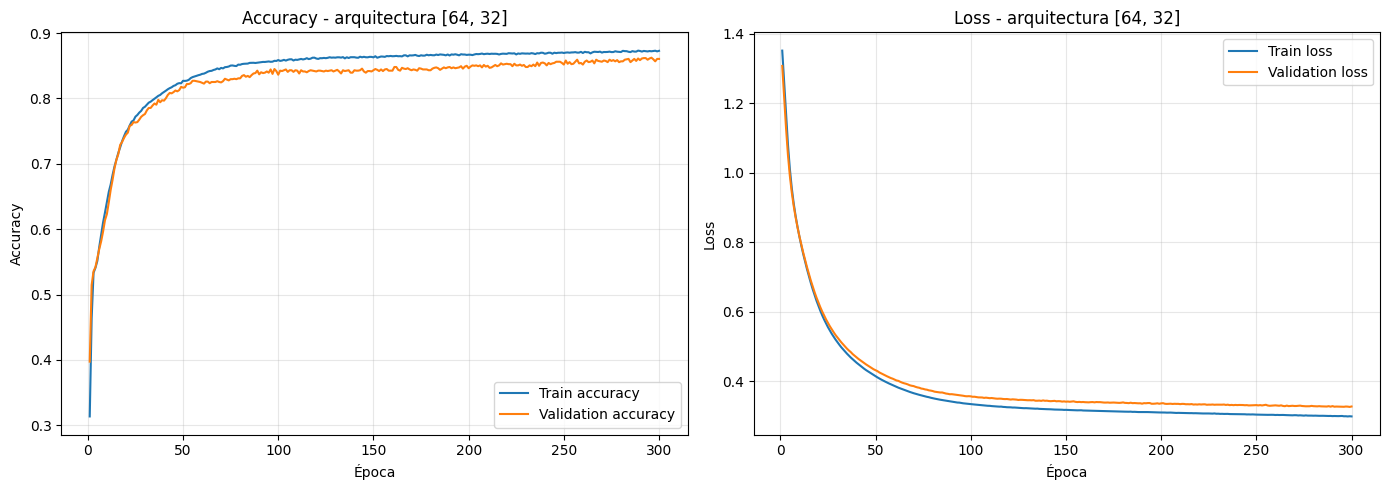

In [7]:
best_arch_row = arch_results_df.iloc[0]
best_architecture = best_arch_row["architecture"]
best_arch_name = best_arch_row["name"]

print("Mejor arquitectura:", best_architecture)
print(f"Mejor época: {best_arch_row['best_epoch']}")
print(f"Train accuracy: {best_arch_row['train_acc']:.4f}")
print(f"Validation accuracy: {best_arch_row['val_acc']:.4f}")
print(f"Train loss: {best_arch_row['train_loss']:.4f}")
print(f"Validation loss: {best_arch_row['val_loss']:.4f}")
print(f"Gap de accuracy: {best_arch_row['gap_acc']:.4f}")

plot_history(arch_histories[best_arch_name], title_suffix=f"- arquitectura {best_architecture}")

### 6.2 Gráficas útiles de la fase de arquitectura

Estas representaciones son especialmente útiles para la memoria porque muestran:
- el rendimiento en entrenamiento y validación,
- la capacidad de generalización de cada arquitectura.

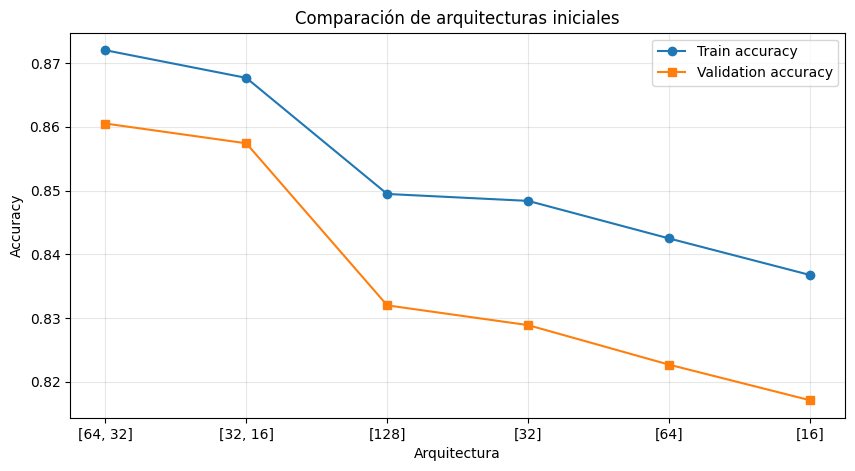

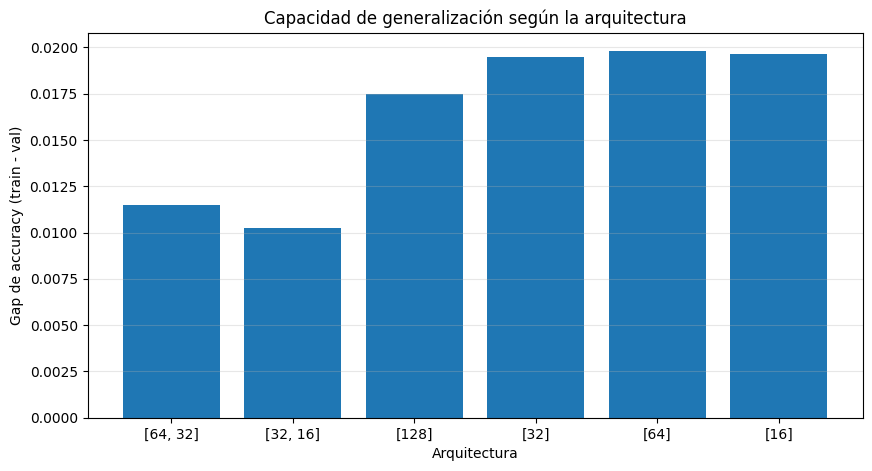

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(arch_results_df["name"], arch_results_df["train_acc"], marker="o", label="Train accuracy")
plt.plot(arch_results_df["name"], arch_results_df["val_acc"], marker="s", label="Validation accuracy")
plt.xlabel("Arquitectura")
plt.ylabel("Accuracy")
plt.title("Comparación de arquitecturas iniciales")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(arch_results_df["name"], arch_results_df["gap_acc"])
plt.xlabel("Arquitectura")
plt.ylabel("Gap de accuracy (train - val)")
plt.title("Capacidad de generalización según la arquitectura")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 7. Fase B · Ajuste del learning rate

Una vez fijada la mejor arquitectura, se estudia la influencia del **learning rate** manteniendo constante el resto de la configuración.

In [9]:
learning_rates = [0.01, 0.005, 0.001, 0.0005]

lr_experiments = [
    {
        "name": f"lr_{lr}",
        "architecture": best_architecture,
        "learning_rate": lr,
        "momentum": base_momentum,
        "l2": 0.0,
        "dropout": 0.0
    }
    for lr in learning_rates
]

lr_results_df, lr_histories, lr_models = run_experiments(
    lr_experiments,
    n_epochs=base_epochs,
    batch_size=base_batch_size
)

display(lr_results_df)

,name,architecture,learning_rate,momentum,l2,dropout,best_epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,lr_0.01,"[64, 32]",0.0100,0.9,0.0,0.0,62,0.291329,0.321399,0.878825,0.864848,0.013977
1,lr_0.005,"[64, 32]",0.0050,0.9,0.0,0.0,127,0.281289,0.318634,0.882544,0.864228,0.018316
2,lr_0.001,"[64, 32]",0.0010,0.9,0.0,0.0,298,0.300132,0.330493,0.875881,0.861748,0.014133
3,lr_0.0005,"[64, 32]",0.0005,0.9,0.0,0.0,300,0.319627,0.346610,0.863485,0.845629,0.017856


Mejor learning rate: 0.01
Mejor época: 62
Train accuracy: 0.8788
Validation accuracy: 0.8648
Train loss: 0.2913
Validation loss: 0.3214


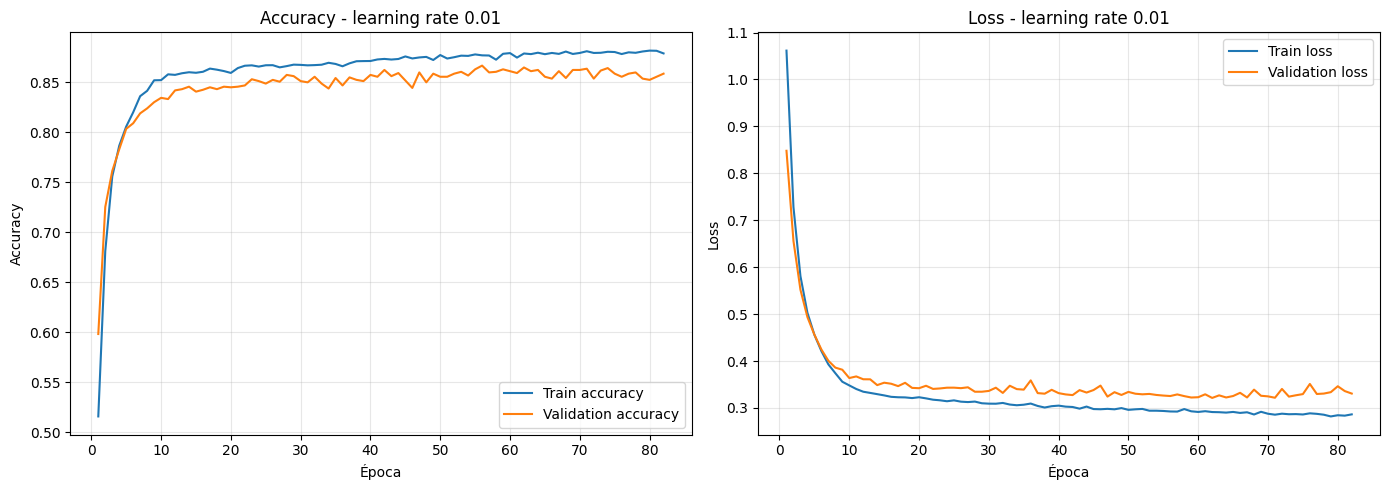

In [10]:
best_lr_row = lr_results_df.iloc[0]
best_lr = float(best_lr_row["learning_rate"])
best_lr_name = best_lr_row["name"]

print("Mejor learning rate:", best_lr)
print(f"Mejor época: {best_lr_row['best_epoch']}")
print(f"Train accuracy: {best_lr_row['train_acc']:.4f}")
print(f"Validation accuracy: {best_lr_row['val_acc']:.4f}")
print(f"Train loss: {best_lr_row['train_loss']:.4f}")
print(f"Validation loss: {best_lr_row['val_loss']:.4f}")

plot_history(lr_histories[best_lr_name], title_suffix=f"- learning rate {best_lr}")

**Discusión de la fase B**

- Con `lr = 0.01` el modelo converge en **62 épocas** (el *early stopping* lo detiene), frente a las ~300 que necesita `lr = 0.001`.
- La *accuracy* en dev apenas cambia entre 0.01, 0.005 y 0.001 (86,5 %, 86,4 % y 86,2 %). Estas diferencias son menores que la variabilidad entre ejecuciones (ver fase E), así que la ventaja real de `lr = 0.01` es la **velocidad de convergencia**, no la precisión.
- `lr = 0.0005` es demasiado lento: no converge en 300 épocas (84,6 %).

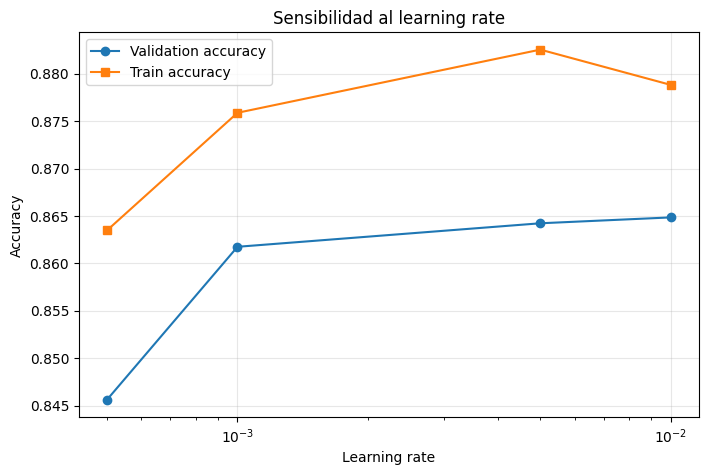

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(lr_results_df["learning_rate"], lr_results_df["val_acc"], marker="o", label="Validation accuracy")
plt.plot(lr_results_df["learning_rate"], lr_results_df["train_acc"], marker="s", label="Train accuracy")
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Accuracy")
plt.title("Sensibilidad al learning rate")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 8. Fase C · Ajuste del momentum

Tras fijar la arquitectura y el learning rate, se evalúan distintos valores del parámetro **momentum** para comprobar cuál proporciona mejor convergencia y mejor generalización.

In [12]:
momentum_values = [0.8, 0.9, 0.95]

momentum_experiments = [
    {
        "name": f"momentum_{mom}",
        "architecture": best_architecture,
        "learning_rate": best_lr,
        "momentum": mom,
        "l2": 0.0,
        "dropout": 0.0
    }
    for mom in momentum_values
]

momentum_results_df, momentum_histories, momentum_models = run_experiments(
    momentum_experiments,
    n_epochs=base_epochs,
    batch_size=base_batch_size
)

display(momentum_results_df)

,name,architecture,learning_rate,momentum,l2,dropout,best_epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,momentum_0.95,"[64, 32]",0.01,0.95,0.0,0.0,51,0.282695,0.318230,0.882389,0.876007,0.006382
1,momentum_0.9,"[64, 32]",0.01,0.90,0.0,0.0,42,0.294860,0.316125,0.877198,0.866708,0.010490
2,momentum_0.8,"[64, 32]",0.01,0.80,0.0,0.0,124,0.284076,0.320221,0.881615,0.862988,0.018626


Mejor momentum: 0.95
Mejor época: 51
Train accuracy: 0.8824
Validation accuracy: 0.8760
Train loss: 0.2827
Validation loss: 0.3182


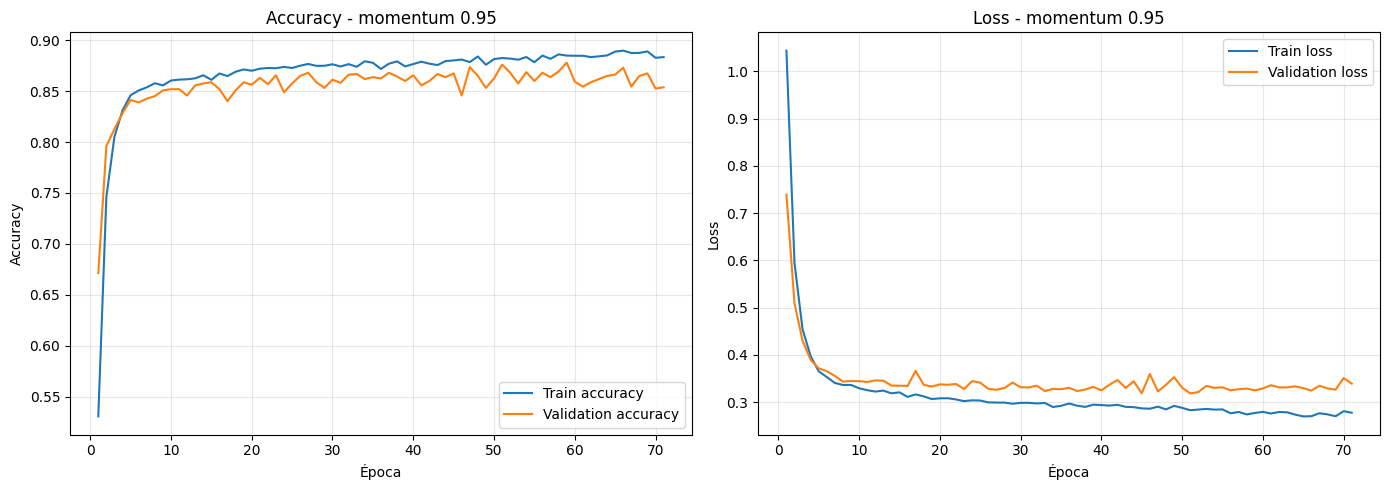

In [13]:
best_momentum_row = momentum_results_df.iloc[0]
best_momentum = float(best_momentum_row["momentum"])
best_momentum_name = best_momentum_row["name"]

print("Mejor momentum:", best_momentum)
print(f"Mejor época: {best_momentum_row['best_epoch']}")
print(f"Train accuracy: {best_momentum_row['train_acc']:.4f}")
print(f"Validation accuracy: {best_momentum_row['val_acc']:.4f}")
print(f"Train loss: {best_momentum_row['train_loss']:.4f}")
print(f"Validation loss: {best_momentum_row['val_loss']:.4f}")

plot_history(momentum_histories[best_momentum_name], title_suffix=f"- momentum {best_momentum}")

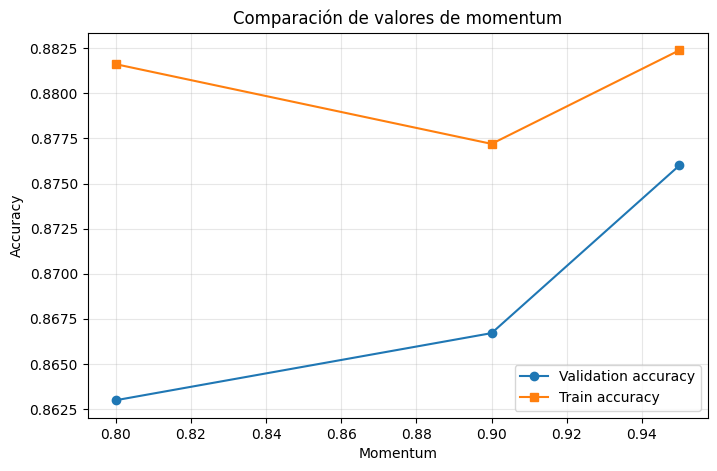

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(momentum_results_df["momentum"], momentum_results_df["val_acc"], marker="o", label="Validation accuracy")
plt.plot(momentum_results_df["momentum"], momentum_results_df["train_acc"], marker="s", label="Train accuracy")
plt.xlabel("Momentum")
plt.ylabel("Accuracy")
plt.title("Comparación de valores de momentum")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Discusión de la fase C**

Con `momentum = 0.95` se obtiene la mejor *accuracy* en dev (**87,6 %**) y la menor diferencia entre entrenamiento y dev (0,6 puntos). Un momentum alto suaviza la dirección de descenso y acelera la convergencia con este *learning rate*.

## 9. Fase D · Regularización

En esta fase se compara el efecto de dos estrategias de regularización:
- **L2**
- **Dropout**

El objetivo es reducir el sobreajuste manteniendo o mejorando el rendimiento sobre validación.

### 9.1 Ajuste de regularización L2

In [15]:
l2_values = [0.0, 0.0001, 0.0003, 0.001]

l2_experiments = [
    {
        "name": f"l2_{l2_value}",
        "architecture": best_architecture,
        "learning_rate": best_lr,
        "momentum": best_momentum,
        "l2": l2_value,
        "dropout": 0.0
    }
    for l2_value in l2_values
]

l2_results_df, l2_histories, l2_models = run_experiments(
    l2_experiments,
    n_epochs=base_epochs,
    batch_size=base_batch_size
)

display(l2_results_df)

,name,architecture,learning_rate,momentum,l2,dropout,best_epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,l2_0.0,"[64, 32]",0.01,0.95,0.0000,0.0,68,0.270968,0.312402,0.885489,0.874148,0.011341
1,l2_0.0003,"[64, 32]",0.01,0.95,0.0003,0.0,87,0.301335,0.339163,0.884171,0.867328,0.016843
2,l2_0.001,"[64, 32]",0.01,0.95,0.0010,0.0,47,0.352399,0.364761,0.866507,0.864848,0.001658
3,l2_0.0001,"[64, 32]",0.01,0.95,0.0001,0.0,63,0.292754,0.327499,0.883009,0.864228,0.018781


Mejor valor de L2: 0.0
Mejor época: 68
Train accuracy: 0.8855
Validation accuracy: 0.8741


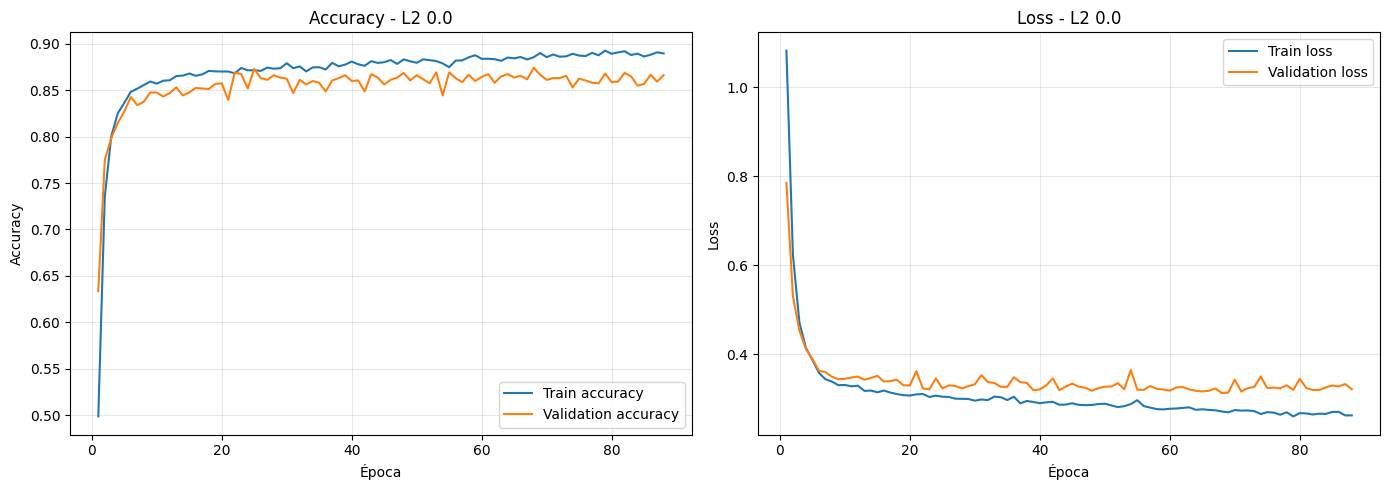

In [16]:
best_l2_row = l2_results_df.iloc[0]
best_l2 = float(best_l2_row["l2"])
best_l2_name = best_l2_row["name"]

print("Mejor valor de L2:", best_l2)
print(f"Mejor época: {best_l2_row['best_epoch']}")
print(f"Train accuracy: {best_l2_row['train_acc']:.4f}")
print(f"Validation accuracy: {best_l2_row['val_acc']:.4f}")

plot_history(l2_histories[best_l2_name], title_suffix=f"- L2 {best_l2}")

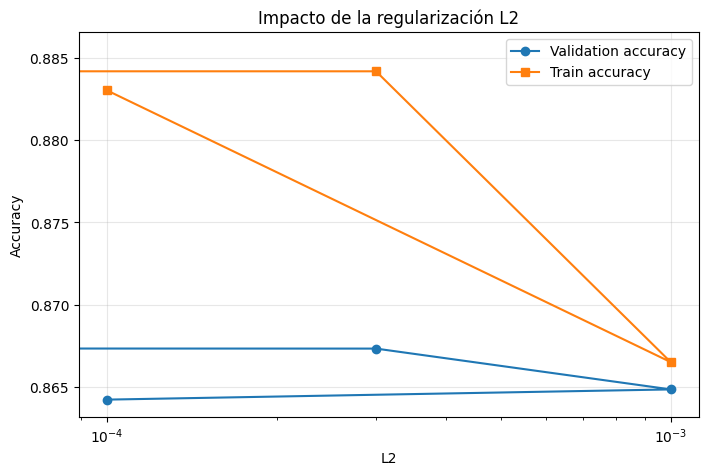

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(l2_results_df["l2"], l2_results_df["val_acc"], marker="o", label="Validation accuracy")
plt.plot(l2_results_df["l2"], l2_results_df["train_acc"], marker="s", label="Train accuracy")
plt.xscale("log")
plt.xlabel("L2")
plt.ylabel("Accuracy")
plt.title("Impacto de la regularización L2")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### 9.2 Ajuste de Dropout

In [18]:
dropout_values = [0.0, 0.1, 0.2, 0.3]

dropout_experiments = [
    {
        "name": f"dropout_{dropout}",
        "architecture": best_architecture,
        "learning_rate": best_lr,
        "momentum": best_momentum,
        "l2": 0.0,
        "dropout": dropout
    }
    for dropout in dropout_values
]

dropout_results_df, dropout_histories, dropout_models = run_experiments(
    dropout_experiments,
    n_epochs=base_epochs,
    batch_size=base_batch_size
)

display(dropout_results_df)

,name,architecture,learning_rate,momentum,l2,dropout,best_epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,dropout_0.0,"[64, 32]",0.01,0.95,0.0,0.0,34,0.294836,0.318178,0.876811,0.870428,0.006383
1,dropout_0.2,"[64, 32]",0.01,0.95,0.0,0.2,88,0.335462,0.330160,0.861238,0.862368,-0.001130
2,dropout_0.1,"[64, 32]",0.01,0.95,0.0,0.1,66,0.319917,0.326264,0.868443,0.861128,0.007315
3,dropout_0.3,"[64, 32]",0.01,0.95,0.0,0.3,62,0.374427,0.335882,0.842721,0.858648,-0.015927


Mejor valor de Dropout: 0.0
Mejor época: 34
Train accuracy: 0.8768
Validation accuracy: 0.8704


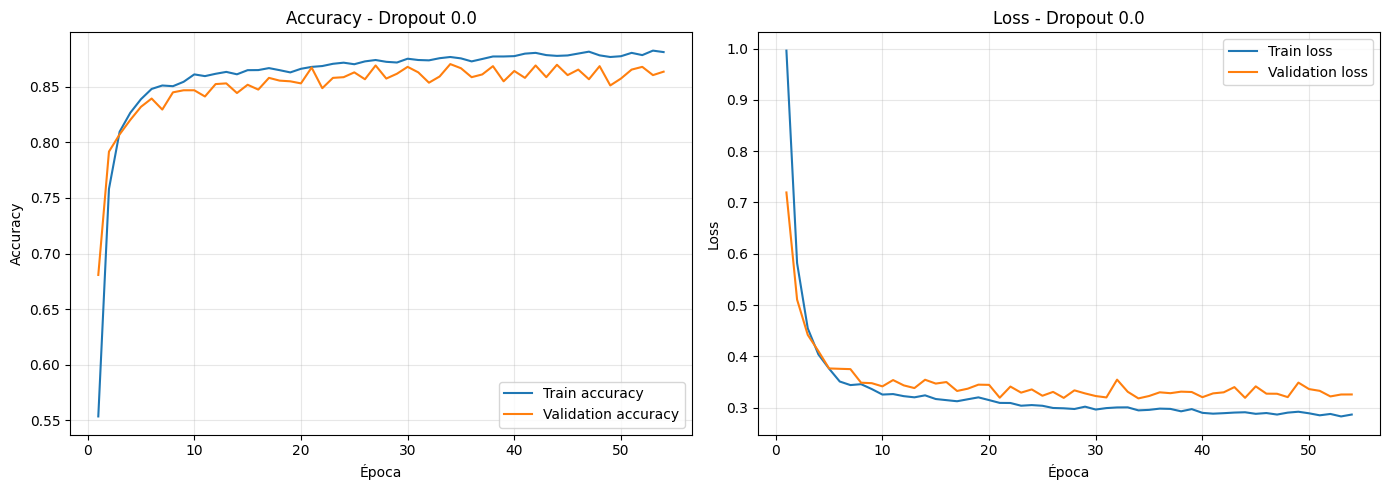

In [19]:
best_dropout_row = dropout_results_df.iloc[0]
best_dropout = float(best_dropout_row["dropout"])
best_dropout_name = best_dropout_row["name"]

print("Mejor valor de Dropout:", best_dropout)
print(f"Mejor época: {best_dropout_row['best_epoch']}")
print(f"Train accuracy: {best_dropout_row['train_acc']:.4f}")
print(f"Validation accuracy: {best_dropout_row['val_acc']:.4f}")

plot_history(dropout_histories[best_dropout_name], title_suffix=f"- Dropout {best_dropout}")

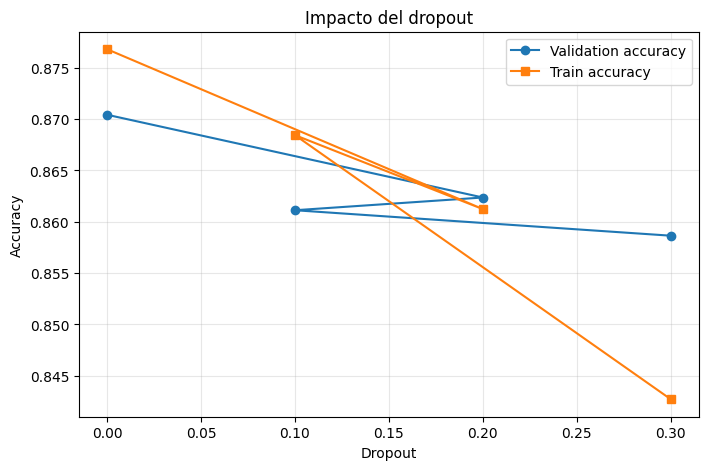

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(dropout_results_df["dropout"], dropout_results_df["val_acc"], marker="o", label="Validation accuracy")
plt.plot(dropout_results_df["dropout"], dropout_results_df["train_acc"], marker="s", label="Train accuracy")
plt.xlabel("Dropout")
plt.ylabel("Accuracy")
plt.title("Impacto del dropout")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Discusión de la fase D**

**Ni L2 ni *dropout* mejoran el modelo:** el mejor valor de ambos es 0. Tiene sentido, porque el modelo **no sobreajusta** (la diferencia entre entrenamiento y dev es de ~1 punto). La regularización reduce la varianza, pero aquí el problema es el **sesgo**: el error de entrenamiento (~12 %) sigue por encima del error bayesiano (10 %). Con *dropout* alto (0,2–0,3), la *accuracy* de entrenamiento llega a quedar por debajo de la de dev, una señal clara de que se está limitando un modelo que no lo necesita.

## 10. Fase E · Comparación final entre L2 y Dropout

Una vez ajustados ambos métodos de regularización, se comparan sus mejores configuraciones para decidir cuál será el **modelo Momentum definitivo**.

In [21]:
final_candidates = [
    {
        "name": "Best_L2",
        "architecture": best_architecture,
        "learning_rate": best_lr,
        "momentum": best_momentum,
        "l2": best_l2,
        "dropout": 0.0
    },
    {
        "name": "Best_Dropout",
        "architecture": best_architecture,
        "learning_rate": best_lr,
        "momentum": best_momentum,
        "l2": 0.0,
        "dropout": best_dropout
    }
]

final_results_df, final_histories, final_models = run_experiments(
    final_candidates,
    n_epochs=base_epochs,
    batch_size=base_batch_size
)

display(final_results_df)

,name,architecture,learning_rate,momentum,l2,dropout,best_epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,Best_L2,"[64, 32]",0.01,0.95,0.0,0.0,38,0.296455,0.316525,0.873712,0.865468,0.008244
1,Best_Dropout,"[64, 32]",0.01,0.95,0.0,0.0,51,0.279582,0.317812,0.883474,0.862368,0.021106


**Nota sobre la fase E: la variabilidad entre ejecuciones**

Como el mejor valor de L2 y el mejor de *dropout* fueron 0, los dos candidatos `Best_L2` y `Best_Dropout` son en realidad **la misma configuración**: [64, 32], `lr = 0.01`, `momentum = 0.95` y sin regularización. La diferencia entre ellos (86,5 % frente a 86,2 %) se debe solo a la **aleatoriedad del entrenamiento**: la inicialización de los pesos y el orden de los *mini-batches*.

Esa misma configuración se ha entrenado **5 veces** a lo largo del notebook:

| Ejecución | Accuracy en dev |
|---|---|
| Fase C (`momentum_0.95`) | 0,8760 |
| Fase D (`l2_0.0`) | 0,8741 |
| Fase D (`dropout_0.0`) | 0,8704 |
| Fase E (`Best_L2`) | 0,8655 |
| Fase E (`Best_Dropout`) | 0,8624 |
| **Media ± desviación típica** | **0,870 ± 0,006** |

**Conclusión metodológica:** la variación entre ejecuciones (hasta 1,4 puntos) es del mismo orden que muchas de las diferencias usadas para decidir entre hiperparámetros. Para que las comparaciones sean fiables, habría que **fijar la semilla** y, mejor aún, **promediar varias ejecuciones** por configuración. Aun así, las decisiones con diferencias grandes (dos capas frente a una, `lr = 0.0005` demasiado lento, regularización innecesaria) siguen siendo válidas.

Modelo final seleccionado: Best_L2
Arquitectura final: [64, 32]
Learning rate final: 0.01
Momentum final: 0.95
L2 final: 0.0
Dropout final: 0.0
Validation accuracy: 0.8655
Validation loss: 0.3165


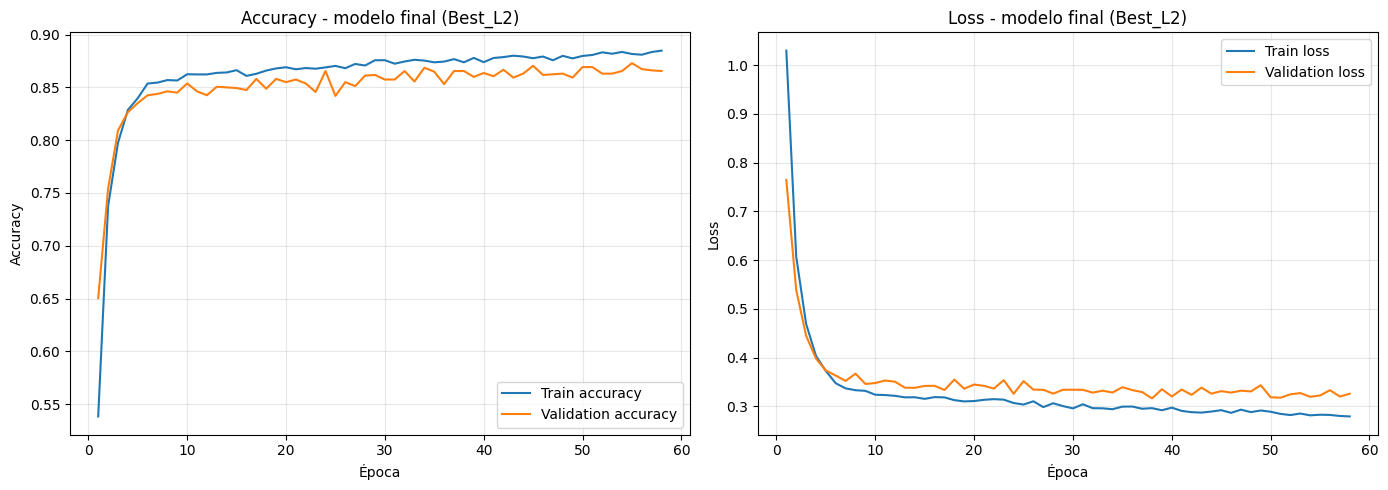

In [22]:
best_final_row = final_results_df.iloc[0]
best_candidate_name = best_final_row["name"]
best_history = final_histories[best_candidate_name]
best_final_model = final_models[best_candidate_name]

FINAL_ARCHITECTURE = best_final_row["architecture"]
FINAL_LR = float(best_final_row["learning_rate"])
FINAL_MOMENTUM = float(best_final_row["momentum"])
FINAL_L2 = float(best_final_row["l2"])
FINAL_DROPOUT = float(best_final_row["dropout"])

print("Modelo final seleccionado:", best_candidate_name)
print("Arquitectura final:", FINAL_ARCHITECTURE)
print("Learning rate final:", FINAL_LR)
print("Momentum final:", FINAL_MOMENTUM)
print("L2 final:", FINAL_L2)
print("Dropout final:", FINAL_DROPOUT)
print(f"Validation accuracy: {best_final_row['val_acc']:.4f}")
print(f"Validation loss: {best_final_row['val_loss']:.4f}")

plot_history(best_history, title_suffix=f"- modelo final ({best_candidate_name})")

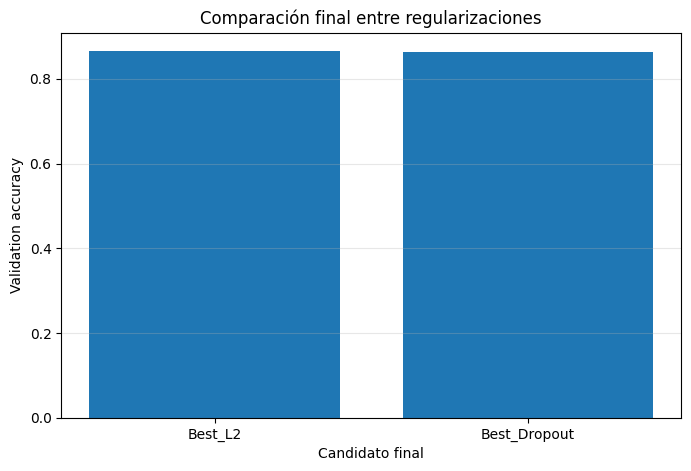

In [23]:
plt.figure(figsize=(8, 5))
plt.bar(final_results_df["name"], final_results_df["val_acc"])
plt.xlabel("Candidato final")
plt.ylabel("Validation accuracy")
plt.title("Comparación final entre regularizaciones")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 11. Evaluación final sobre el conjunto de test

Una vez escogido el mejor modelo en validación, se evalúa sobre **test**, que no ha sido usado durante el proceso de ajuste.  
Esta sección permite obtener:
- pérdida y accuracy final,
- matriz de confusión,
- classification report,
- curvas y figuras útiles para la memoria.

In [24]:
test_loss, test_acc = best_final_model.evaluate(x_test, t_test, verbose=0)

print("Resultados finales en test")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Resultados finales en test
Test loss: 0.3357
Test accuracy: 0.8594


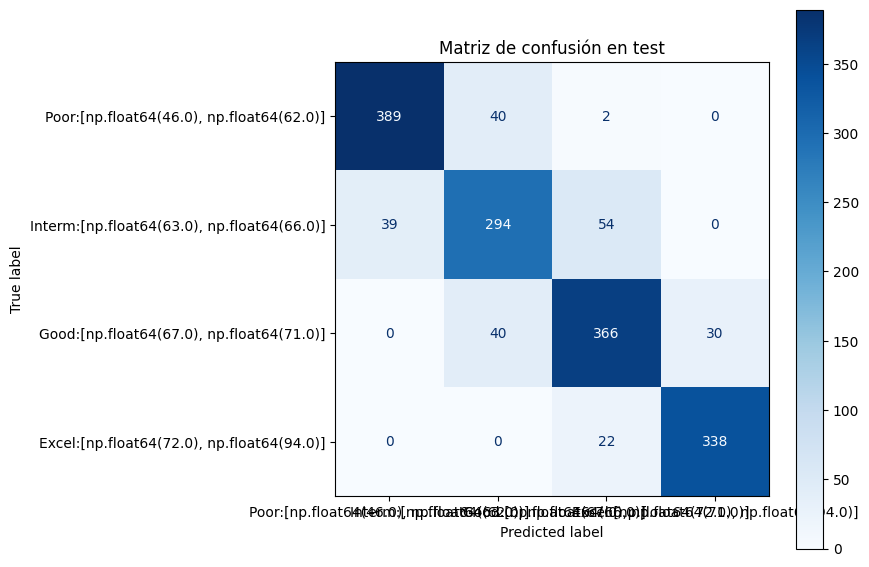

In [25]:
y_test_true = np.argmax(t_test, axis=1)
y_test_pred = np.argmax(best_final_model.predict(x_test, verbose=0), axis=1)

cm = confusion_matrix(y_test_true, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Matriz de confusión en test")
plt.show()

In [26]:
report = classification_report(y_test_true, y_test_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
report_df = pd.DataFrame(report).transpose()
display(report_df)

,precision,recall,f1-score,support
"Poor:[np.float64(46.0), np.float64(62.0)]",0.908879,0.902552,0.905704,431.000000
"Interm:[np.float64(63.0), np.float64(66.0)]",0.786096,0.759690,0.772668,387.000000
"Good:[np.float64(67.0), np.float64(71.0)]",0.824324,0.839450,0.831818,436.000000
"Excel:[np.float64(72.0), np.float64(94.0)]",0.918478,0.938889,0.928571,360.000000
accuracy,0.859356,0.859356,0.859356,0.859356
macro avg,0.859444,0.860145,0.859690,1614.000000
weighted avg,0.858738,0.859356,0.858946,1614.000000


### Análisis de los resultados en test

**Accuracy en test: 85,9 %** (error del 14,1 %).

**Descomposición del error** respecto al error bayesiano del 10 %:

| | Error | Diferencia | Interpretación |
|---|---|---|---|
| Bayesiano (ojeador experto) | 10,0 % | | Mínimo alcanzable |
| Entrenamiento | 12,6 % | **2,6 puntos** | **Sesgo evitable** |
| Desarrollo | 13,5 % | 0,8 puntos | Varianza |
| Test | 14,1 % | 0,6 puntos | Diferencia dev → test (ligero ajuste a dev) |

El problema principal es el **sesgo**: el modelo no llega a aprender todo lo que los datos permiten. Los siguientes pasos serían, por tanto, **aumentar la capacidad** (más neuronas o capas), **entrenar más tiempo** u otros optimizadores, y no añadir más regularización.

**Matriz de confusión:**

- **De los 227 errores, 225 son entre clases contiguas** (Poor ↔ Intermediate, Intermediate ↔ Good, Good ↔ Excellent). Solo 2 jugadores Poor se clasifican como Good, y ningún error salta más de una clase. El modelo ha aprendido el **orden** de las clases.
- **Intermediate es la clase más difícil** (recall 76 %). Abarca solo 4 puntos de *overall* (63–66) y limita con dos clases, así que un jugador de 63 se parece mucho a uno de 62 (Poor).
- **Excellent** (recall 94 %) y **Poor** (90 %) son las más fáciles, porque solo tienen una clase vecina.

## Conclusiones

- La red final ([64, 32] ReLU + softmax, SGD con `lr = 0.01` y `momentum = 0.95`, sin regularización, *early stopping* con paciencia 20) alcanza un **85,9 % de *accuracy* en test**, a unos 4 puntos del límite del 10 % de error de un experto.
- La **profundidad** (2 capas ocultas) y un **learning rate y momentum altos** fueron las decisiones con más impacto. La regularización no ayudó, porque el modelo no sobreajusta.
- Los errores son casi siempre entre clases contiguas, y se concentran en la clase Intermediate, que es la más estrecha.
- **Lección aprendida:** la variabilidad entre ejecuciones (±0,6 puntos) es comparable a muchas diferencias entre hiperparámetros. Fijar semillas y promediar varias ejecuciones es imprescindible para comparar modelos con rigor.